
# FINAL PROJECT - IMAGE RETRIEVAL (CBIR)

### Nama      : Achmal Farhan Ashidiqy
### NIM       : 202210370311298
### Kelas     : Temu Kembali Citra B
### Dataset   : Plant Leaf Image Dataset (8 Classes)
### Link Dataset : https://www.kaggle.com/datasets/mahmoudshaheen1134/plant-leaf-image-dataset
--------------------------------------------------------------------

# Mount Google Drive

In [8]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Import Library & Set Random Seet

In [7]:
import os
import zipfile
import random
import numpy as np
import pandas as pd
from glob import glob
from tqdm import tqdm
from collections import Counter
import cv2
from sklearn.cluster import KMeans
from skimage.feature import local_binary_pattern, hog
from sklearn.preprocessing import normalize
from scipy.spatial.distance import euclidean, cityblock as manhattan, canberra, cosine


SEED = 42
random.seed(SEED)
np.random.seed(SEED)


# Definisi Path Dataset di Google Drive & Ekstraksi Dataset zip

In [9]:
# -------------------------------
# Path Configuration
# -------------------------------
ZIP_PATH = "/content/drive/MyDrive/SMT 7/TKC/plant-leaf-image.zip"
EXTRACT_PATH = "/content/plant_leaf_dataset2"

# -------------------------------
# Extract Dataset (Safe Re-run)
# -------------------------------
os.makedirs(EXTRACT_PATH, exist_ok=True)

if len(os.listdir(EXTRACT_PATH)) == 0:
    print("📦 Mengekstrak dataset plant-leaf-image.zip ...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)
    print("✅ Ekstraksi selesai")
else:
    print("ℹ️ Dataset sudah tersedia, lewati ekstraksi")

# -------------------------------
# Auto-detect Data Root
# -------------------------------
print("\n🔍 Mendeteksi struktur dataset...")

subdirs = [
    d for d in os.listdir(EXTRACT_PATH)
    if os.path.isdir(os.path.join(EXTRACT_PATH, d))
]

if len(subdirs) == 1:
    DATA_ROOT = os.path.join(EXTRACT_PATH, subdirs[0])
    print(f"📁 Inner folder terdeteksi sebagai data root: {DATA_ROOT}")
else:
    DATA_ROOT = EXTRACT_PATH
    print(f"📁 Menggunakan extract path langsung sebagai data root")

# -------------------------------
# Validasi Kelas
# -------------------------------
classes = sorted([
    d for d in os.listdir(DATA_ROOT)
    if os.path.isdir(os.path.join(DATA_ROOT, d))
])

if len(classes) < 5:
    raise ValueError(
        f"❌ Dataset tidak memenuhi syarat minimal kelas (ditemukan {len(classes)})"
    )

print(f"\n✅ Ditemukan {len(classes)} kelas tanaman:")
for i, cls in enumerate(classes, 1):
    print(f"  {i:02d}. {cls}")

# -------------------------------
# Load Image Paths & Labels
# -------------------------------
image_records = []

VALID_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")

print("\n📸 Memindai gambar per kelas...")
for cls in classes:
    cls_dir = os.path.join(DATA_ROOT, cls)
    imgs = [
        os.path.join(cls_dir, f)
        for f in os.listdir(cls_dir)
        if f.lower().endswith(VALID_EXT)
    ]

    print(f"  🌿 {cls:<25}: {len(imgs)} gambar")

    for img_path in imgs:
        image_records.append({
            "path": img_path,
            "label": cls
        })

df_images = pd.DataFrame(image_records)

# -------------------------------
# Final Validation
# -------------------------------
print("\n📊 Ringkasan Dataset:")
print(f"Total gambar : {len(df_images)}")
print(f"Total kelas  : {df_images['label'].nunique()}")

if len(df_images) < 300:
    print("⚠️ Peringatan: jumlah gambar < 300 (disarankan tambah data)")
else:
    print("✅ Dataset memenuhi ketentuan UAS")

df_images.head()

ℹ️ Dataset sudah tersedia, lewati ekstraksi

🔍 Mendeteksi struktur dataset...
📁 Inner folder terdeteksi sebagai data root: /content/plant_leaf_dataset2/New_data

✅ Ditemukan 8 kelas tanaman:
  01. Apple
  02. Berry
  03. Fig
  04. Guava
  05. Orange
  06. Palm
  07. Persimmon
  08. Tomato

📸 Memindai gambar per kelas...
  🌿 Apple                    : 519 gambar
  🌿 Berry                    : 340 gambar
  🌿 Fig                      : 508 gambar
  🌿 Guava                    : 520 gambar
  🌿 Orange                   : 547 gambar
  🌿 Palm                     : 468 gambar
  🌿 Persimmon                : 527 gambar
  🌿 Tomato                   : 159 gambar

📊 Ringkasan Dataset:
Total gambar : 3588
Total kelas  : 8
✅ Dataset memenuhi ketentuan UAS


,path,label
0,/content/plant_leaf_dataset2/New_data/Apple/IM...,Apple
1,/content/plant_leaf_dataset2/New_data/Apple/IM...,Apple
2,/content/plant_leaf_dataset2/New_data/Apple/IM...,Apple
3,/content/plant_leaf_dataset2/New_data/Apple/IM...,Apple
4,/content/plant_leaf_dataset2/New_data/Apple/IM...,Apple


# Stratified Gallery / Query Split (80:20)

## Parameter Split, Validasi Awal, dan Analisis Distribusi Awal

In [10]:
GALLERY_RATIO = 0.8
MIN_QUERY_PER_CLASS = 1

print("🔧 Konfigurasi split:")
print(f"  - Gallery ratio : {GALLERY_RATIO}")
print(f"  - Query ratio   : {1 - GALLERY_RATIO}")

print("\n📊 Distribusi gambar awal per kelas:")
class_counts = df_images["label"].value_counts().sort_index()
class_counts


🔧 Konfigurasi split:
  - Gallery ratio : 0.8
  - Query ratio   : 0.19999999999999996

📊 Distribusi gambar awal per kelas:


,count
label,
Apple,519
Berry,340
Fig,508
Guava,520
Orange,547
Palm,468
Persimmon,527
Tomato,159


## Stratified Split per Kelas

In [11]:
gallery_records = []
query_records = []

print("\n✂️ Melakukan stratified split per kelas...")

for cls, count in class_counts.items():
    cls_df = df_images[df_images["label"] == cls].sample(
        frac=1.0, random_state=SEED
    )  # shuffle deterministik

    split_idx = int(len(cls_df) * GALLERY_RATIO)

    # Safety check: pastikan query tidak kosong
    if len(cls_df) - split_idx < MIN_QUERY_PER_CLASS:
        split_idx = len(cls_df) - MIN_QUERY_PER_CLASS

    gallery_part = cls_df.iloc[:split_idx]
    query_part   = cls_df.iloc[split_idx:]

    gallery_records.append(gallery_part)
    query_records.append(query_part)

    print(f"  🌿 {cls:<20} → Gallery: {len(gallery_part):3d}, Query: {len(query_part):3d}")



✂️ Melakukan stratified split per kelas...
  🌿 Apple                → Gallery: 415, Query: 104
  🌿 Berry                → Gallery: 272, Query:  68
  🌿 Fig                  → Gallery: 406, Query: 102
  🌿 Guava                → Gallery: 416, Query: 104
  🌿 Orange               → Gallery: 437, Query: 110
  🌿 Palm                 → Gallery: 374, Query:  94
  🌿 Persimmon            → Gallery: 421, Query: 106
  🌿 Tomato               → Gallery: 127, Query:  32


## Menggabungkan & Membentuk DataFrame Final

In [12]:
df_gallery = pd.concat(gallery_records).reset_index(drop=True)
df_query   = pd.concat(query_records).reset_index(drop=True)

print("\n📦 Ukuran dataset setelah split:")
print(f"  Gallery set : {df_gallery.shape}")
print(f"  Query set   : {df_query.shape}")



📦 Ukuran dataset setelah split:
  Gallery set : (2868, 2)
  Query set   : (720, 2)


## Critical Validation

In [13]:
print("\n🔍 Validasi konsistensi kelas:")

print("Kelas di gallery:", df_gallery["label"].nunique())
print("Kelas di query  :", df_query["label"].nunique())

assert set(df_gallery["label"]) == set(df_query["label"]), \
    "❌ Kelas gallery dan query tidak konsisten!"


total_images = len(df_gallery) + len(df_query)

print("\n📐 Rasio global:")
print(f"  Total gambar : {total_images}")
print(f"  Gallery (%)  : {len(df_gallery)/total_images:.2%}")
print(f"  Query (%)    : {len(df_query)/total_images:.2%}")


split_summary = pd.DataFrame({
    "Gallery": df_gallery["label"].value_counts(),
    "Query": df_query["label"].value_counts()
}).sort_index()

split_summary



🔍 Validasi konsistensi kelas:
Kelas di gallery: 8
Kelas di query  : 8

📐 Rasio global:
  Total gambar : 3588
  Gallery (%)  : 79.93%
  Query (%)    : 20.07%


,Gallery,Query
label,,
Apple,415,104
Berry,272,68
Fig,406,102
Guava,416,104
Orange,437,110
Palm,374,94
Persimmon,421,106
Tomato,127,32


## Save Split

In [8]:
SPLIT_DIR = "/content/splits"
os.makedirs(SPLIT_DIR, exist_ok=True)

df_gallery.to_csv(os.path.join(SPLIT_DIR, "gallery_set.csv"), index=False)
df_query.to_csv(os.path.join(SPLIT_DIR, "query_set.csv"), index=False)

print("💾 Gallery & Query split disimpan")


💾 Gallery & Query split disimpan


# Pre-processing & Color Representation

## Load Gallery & Query Split

In [14]:
# Path hasil split
SPLIT_DIR = "/content/splits"

gallery_csv = f"{SPLIT_DIR}/gallery_set.csv"
query_csv   = f"{SPLIT_DIR}/query_set.csv"

df_gallery = pd.read_csv(gallery_csv)
df_query   = pd.read_csv(query_csv)

print("📦 Gallery set:", df_gallery.shape)
print("📦 Query set  :", df_query.shape)

df_gallery.head()


📦 Gallery set: (2868, 2)
📦 Query set  : (720, 2)


,path,label
0,/content/plant_leaf_dataset2/New_data/Apple/IM...,Apple
1,/content/plant_leaf_dataset2/New_data/Apple/IM...,Apple
2,/content/plant_leaf_dataset2/New_data/Apple/IM...,Apple
3,/content/plant_leaf_dataset2/New_data/Apple/IM...,Apple
4,/content/plant_leaf_dataset2/New_data/Apple/IM...,Apple


## Fungsi Resize dengan Aspect Ratio & Teknik Image Processing: CLAHE (Contrast Enhancement)

In [15]:
TARGET_SIZE = 224

CLAHE_CLIP = 2.0
CLAHE_GRID = (8, 8)

def resize_with_padding(image, target_size=224):

    h, w = image.shape[:2]
    scale = target_size / max(h, w)

    new_w = int(w * scale)
    new_h = int(h * scale)

    resized = cv2.resize(image, (new_w, new_h))

    pad_w = target_size - new_w
    pad_h = target_size - new_h

    top = pad_h // 2
    bottom = pad_h - top
    left = pad_w // 2
    right = pad_w - left

    padded = cv2.copyMakeBorder(
        resized,
        top, bottom, left, right,
        borderType=cv2.BORDER_CONSTANT,
        value=(0, 0, 0)
    )
    return padded

def apply_clahe_rgb(image, clip=2.0, grid=(8, 8)):
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=grid)
    l_clahe = clahe.apply(l)

    lab_clahe = cv2.merge((l_clahe, a, b))
    enhanced = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2RGB)
    return enhanced


## Fungsi Loader + Pre-processing Lengkap

In [16]:
def load_and_preprocess_image(
    img_path,
    target_size=224,
    apply_clahe_flag=True
):
    """
    Load image → RGB → resize → (opsional) CLAHE
    Mengembalikan:
    - RGB image
    - HSV image
    - Grayscale image
    """
    bgr = cv2.imread(img_path)
    if bgr is None:
        raise ValueError(f"Gagal membaca image: {img_path}")

    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    rgb = resize_with_padding(rgb, target_size)

    if apply_clahe_flag:
        rgb = apply_clahe_rgb(rgb, CLAHE_CLIP, CLAHE_GRID)

    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    return rgb, hsv, gray


## Uji Visual Pre-processing

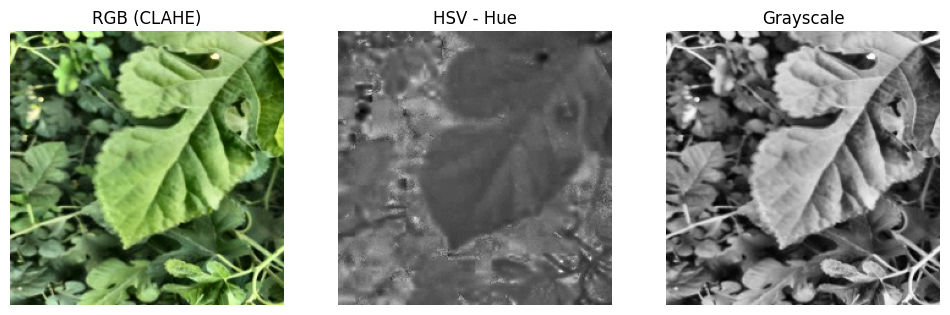

In [17]:
import matplotlib.pyplot as plt

sample_path = df_gallery.sample(1, random_state=SEED)["path"].values[0]

rgb, hsv, gray = load_and_preprocess_image(sample_path)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(rgb)
plt.title("RGB (CLAHE)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(hsv[:, :, 0], cmap="gray")
plt.title("HSV - Hue")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.show()


# Segmentasi

## Feature Extraction Function

In [18]:
def extract_color_histogram(image, color_space="hsv", bins=(8, 8, 8)):
    if color_space == "hsv":
        img = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    else:
        img = image

    hist = cv2.calcHist(
        [img], [0, 1, 2],
        None, bins,
        [0, 256, 0, 256, 0, 256]
    )
    hist = cv2.normalize(hist, hist).flatten()
    return hist


def extract_lbp(image, radius=2, n_points=16):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    gray = cv2.resize(gray, (128, 128))

    lbp = local_binary_pattern(
        gray, n_points, radius, method="uniform"
    )
    hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, n_points + 3),
        range=(0, n_points + 2)
    )
    hist = hist.astype("float")
    hist /= (hist.sum() + 1e-6)
    return hist


def extract_hog(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    gray = cv2.resize(gray, (128, 128))

    feat = hog(
        gray,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )
    return feat


def combine_features(color, lbp, hog,
                     w_color=1.0, w_lbp=1.0, w_hog=1.0):
    return np.concatenate([
        w_color * color,
        w_lbp * lbp,
        w_hog * hog
    ])


## Metode Segmentasi 1 — Otsu Thresholding

In [19]:
def segment_otsu(gray_img):
    """
    Segmentasi menggunakan Otsu Thresholding.
    Input: grayscale image (uint8)
    Output: binary mask (0/1)
    """
    blur = cv2.GaussianBlur(gray_img, (5, 5), 0)
    _, mask = cv2.threshold(
        blur, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Normalisasi mask ke 0/1
    mask = (mask > 0).astype(np.uint8)
    return mask


## Metode Segmentasi 2 — K-Means (HSV Space)

In [20]:
def segment_kmeans_hsv(hsv_img, k=2):
    """
    Segmentasi menggunakan K-Means clustering pada HSV space.
    Diasumsikan cluster terbesar adalah background.
    """
    h, w, c = hsv_img.shape
    pixels = hsv_img.reshape((-1, 3)).astype(np.float32)

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(pixels)

    labels_img = labels.reshape((h, w))

    # Anggap cluster terbesar = background
    unique, counts = np.unique(labels_img, return_counts=True)
    background_label = unique[np.argmax(counts)]

    mask = (labels_img != background_label).astype(np.uint8)
    return mask


## Menerapkan Mask ke Citra (ROI Extraction) & Wrapper Segmentasi

In [21]:
def apply_mask(image, mask):
    """
    Terapkan binary mask ke citra RGB.
    """
    if len(mask.shape) == 2:
        mask_3c = np.repeat(mask[:, :, None], 3, axis=2)
    else:
        mask_3c = mask

    return image * mask_3c


def segment_image(rgb, hsv, gray, method="none"):
    """
    method:
    - 'none'  : tanpa segmentasi
    - 'otsu'  : Otsu thresholding
    - 'kmeans': K-Means clustering
    """
    if method == "none":
        return rgb, None

    if method == "otsu":
        mask = segment_otsu(gray)
    elif method == "kmeans":
        mask = segment_kmeans_hsv(hsv)
    else:
        raise ValueError("Metode segmentasi tidak dikenal")

    segmented = apply_mask(rgb, mask)
    return segmented, mask


## Visualisasi Perbandingan

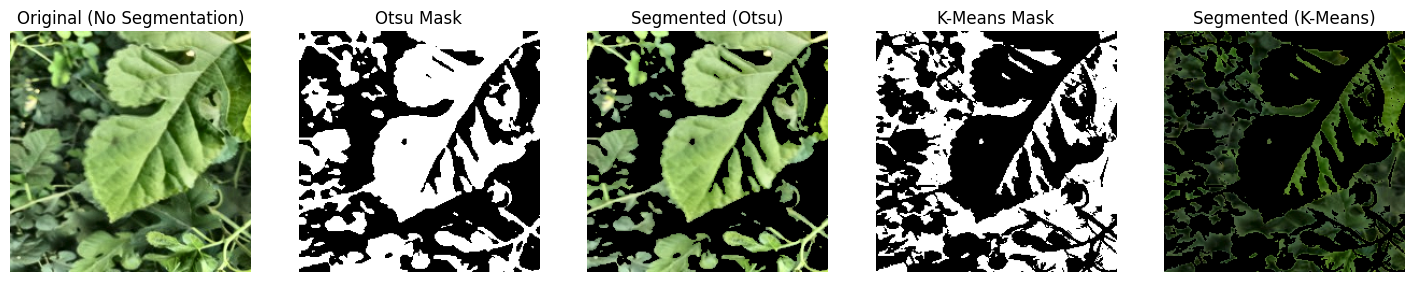

In [22]:
import matplotlib.pyplot as plt

sample_path = df_gallery.sample(1, random_state=SEED)["path"].values[0]
rgb, hsv, gray = load_and_preprocess_image(sample_path)

seg_none, _ = segment_image(rgb, hsv, gray, method="none")
seg_otsu, mask_otsu = segment_image(rgb, hsv, gray, method="otsu")
seg_km, mask_km = segment_image(rgb, hsv, gray, method="kmeans")

plt.figure(figsize=(18, 4))

plt.subplot(1, 5, 1)
plt.imshow(rgb)
plt.title("Original (No Segmentation)")
plt.axis("off")

plt.subplot(1, 5, 2)
plt.imshow(mask_otsu, cmap="gray")
plt.title("Otsu Mask")
plt.axis("off")

plt.subplot(1, 5, 3)
plt.imshow(seg_otsu)
plt.title("Segmented (Otsu)")
plt.axis("off")

plt.subplot(1, 5, 4)
plt.imshow(mask_km, cmap="gray")
plt.title("K-Means Mask")
plt.axis("off")

plt.subplot(1, 5, 5)
plt.imshow(seg_km)
plt.title("Segmented (K-Means)")
plt.axis("off")

plt.show()



## Konfigurasi Eksperimen & Wrapper Feature Extraction + Segmentasi

In [23]:
SEGMENTATION_MODES = {
    "No Segmentation": "none",
    "Otsu Thresholding": "otsu",
    "K-Means Clustering": "kmeans"
}

DISTANCE_FN = manhattan   # berdasarkan hasil terbaik sebelumnya
TOP_K = 10

def extract_features_with_segmentation(image_path, segmentation_mode):
    rgb, hsv, gray = load_and_preprocess_image(image_path)

    segmented, _ = segment_image(
        rgb=rgb,
        hsv=hsv,
        gray=gray,
        method=segmentation_mode
    )

    color_feat = extract_color_histogram(
        segmented,
        color_space="hsv"
    )
    lbp_feat = extract_lbp(segmented)
    hog_feat = extract_hog(segmented)

    return combine_features(color_feat, lbp_feat, hog_feat)


## Loop Eksperimen Retrieval

In [24]:
from tqdm import tqdm
import os

FEATURE_DIR = "features_segmentation"
os.makedirs(FEATURE_DIR, exist_ok=True)

segmentation_results = []


In [27]:
def euclidean(a, b):
    return np.linalg.norm(a - b)

def manhattan(a, b):
    return np.sum(np.abs(a - b))

def canberra(a, b):
    return np.sum(np.abs(a - b) / (np.abs(a) + np.abs(b) + 1e-6))

def retrieve_top_k(
    query_feat,
    gallery_feats,
    gallery_labels,
    k=10,
    distance_fn=euclidean
):
    """
    Mengembalikan Top-K hasil retrieval:
    [(distance, label), ...]
    """

    distances = []

    for feat, label in zip(gallery_feats, gallery_labels):
        d = distance_fn(query_feat, feat)
        distances.append((d, label))

    # Urutkan berdasarkan jarak terkecil
    distances = sorted(distances, key=lambda x: x[0])

    return distances[:k]


In [28]:
for seg_name, seg_mode in SEGMENTATION_MODES.items():
    print(f"\n🔹 Evaluating segmentation: {seg_name}")

    gallery_feat_path = f"{FEATURE_DIR}/gallery_feats_{seg_mode}.npy"
    gallery_label_path = f"{FEATURE_DIR}/gallery_labels_{seg_mode}.npy"

    # ================================
    # 1. GALLERY FEATURE (OFFLINE)
    # ================================
    if os.path.exists(gallery_feat_path):
        print("✔ Loading gallery features from disk...")
        gallery_feats = np.load(gallery_feat_path)
        gallery_labels = np.load(gallery_label_path)
    else:
        print("⏳ Extracting gallery features...")
        gallery_feats = []
        gallery_labels = []

        for _, row in tqdm(df_gallery.iterrows(), total=len(df_gallery)):
            feat = extract_features_with_segmentation(
                row["path"], seg_mode
            )
            gallery_feats.append(feat)
            gallery_labels.append(row["label"])

        gallery_feats = np.array(gallery_feats)
        gallery_labels = np.array(gallery_labels)

        # 🔹 SIMPAN KE DISK (INI JAWABAN UTAMA)
        np.save(gallery_feat_path, gallery_feats)
        np.save(gallery_label_path, gallery_labels)

        print("✔ Gallery features saved.")

    # ================================
    # 2. QUERY EVALUATION (ONLINE)
    # ================================
    correct = 0

    for _, row in tqdm(df_query.iterrows(), total=len(df_query)):
        q_feat = extract_features_with_segmentation(
            row["path"], seg_mode
        )
        q_label = row["label"]

        topk = retrieve_top_k(
            q_feat,
            gallery_feats,
            gallery_labels,
            k=TOP_K,
            distance_fn=DISTANCE_FN
        )

        retrieved_labels = [lbl for _, lbl in topk]
        if q_label in retrieved_labels:
            correct += 1

    recall_k = correct / len(df_query)

    segmentation_results.append({
        "Segmentation Method": seg_name,
        f"Recall@{TOP_K}": recall_k
    })

df_segmentation_eval = pd.DataFrame(segmentation_results)
df_segmentation_eval



🔹 Evaluating segmentation: No Segmentation
✔ Loading gallery features from disk...


100%|██████████| 720/720 [00:38<00:00, 18.81it/s]



🔹 Evaluating segmentation: Otsu Thresholding
⏳ Extracting gallery features...


100%|██████████| 2868/2868 [00:52<00:00, 54.84it/s]


✔ Gallery features saved.


100%|██████████| 720/720 [00:38<00:00, 18.94it/s]



🔹 Evaluating segmentation: K-Means Clustering
⏳ Extracting gallery features...


100%|██████████| 2868/2868 [11:01<00:00,  4.33it/s]


✔ Gallery features saved.


100%|██████████| 720/720 [03:10<00:00,  3.78it/s]


,Segmentation Method,Recall@10
0,No Segmentation,0.997222
1,Otsu Thresholding,0.990278
2,K-Means Clustering,0.973611


#  Feature Extraction & Descriptor

## Fungsi Color Histogram & Fungsi LBP Histogram

In [29]:
def extract_color_histogram(image, color_space="rgb", bins=(8, 8, 8)):
    """
    Extract normalized color histogram from image.
    """
    if color_space == "rgb":
        img = image
    elif color_space == "hsv":
        img = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    else:
        raise ValueError("color_space harus 'rgb' atau 'hsv'")

    hist = cv2.calcHist(
        [img], [0, 1, 2],
        None, bins,
        [0, 256, 0, 256, 0, 256]
    )

    hist = cv2.normalize(hist, hist).flatten()
    return hist


def extract_lbp_histogram(gray, radius=2, points=16):
    """
    Extract LBP histogram from grayscale image.
    """
    lbp = local_binary_pattern(
        gray, points, radius, method="uniform"
    )

    n_bins = points + 2
    hist, _ = np.histogram(
        lbp.ravel(),
        bins=n_bins,
        range=(0, n_bins)
    )

    hist = hist.astype("float")
    hist /= (hist.sum() + 1e-6)
    return hist



## Fungsi HOG & Wrapper Feature Ekstraction

In [30]:
def extract_hog_features(gray,
                         pixels_per_cell=(8, 8),
                         cells_per_block=(2, 2),
                         orientations=9):
    """
    Extract HOG feature vector.
    """
    features = hog(
        gray,
        orientations=orientations,
        pixels_per_cell=pixels_per_cell,
        cells_per_block=cells_per_block,
        block_norm="L2-Hys",
        visualize=False,
        feature_vector=True
    )
    return features


def extract_features_from_path(
    img_path,
    segmentation_mode="none",
    color_space="rgb"
):
    # Load & preprocess
    rgb, hsv, gray = load_and_preprocess_image(img_path)

    # Segmentasi
    segmented, _ = segment_image(
        rgb, hsv, gray, method=segmentation_mode
    )

    # Update gray after segmentation
    gray_seg = cv2.cvtColor(segmented, cv2.COLOR_RGB2GRAY)

    # Feature extraction
    color_feat = extract_color_histogram(
        segmented, color_space=color_space
    )
    lbp_feat = extract_lbp_histogram(gray_seg)
    hog_feat = extract_hog_features(gray_seg)

    return color_feat, lbp_feat, hog_feat


## Combine Feature

In [31]:
def combine_features(
    color_feat,
    lbp_feat,
    hog_feat,
    weights=(1.0, 1.0, 1.0)
):
    """
    Concatenate & weight features.
    """
    combined = np.hstack([
        weights[0] * color_feat,
        weights[1] * lbp_feat,
        weights[2] * hog_feat
    ])

    combined = normalize(
        combined.reshape(1, -1), norm="l2"
    ).flatten()

    return combined


In [32]:
sample_path = df_gallery.sample(1, random_state=SEED)["path"].values[0]

c_feat, l_feat, h_feat = extract_features_from_path(
    sample_path,
    segmentation_mode="kmeans",
    color_space="hsv"
)

combined_feat = combine_features(c_feat, l_feat, h_feat)

print("Dimensi fitur:")
print("  Color:", c_feat.shape)
print("  LBP  :", l_feat.shape)
print("  HOG  :", h_feat.shape)
print("  Combined:", combined_feat.shape)


Dimensi fitur:
  Color: (512,)
  LBP  : (18,)
  HOG  : (26244,)
  Combined: (26774,)


# Similarity Search & Retrieval

## Fungsi Distance & Retrieval

In [33]:
import numpy as np

def euclidean(a, b):
    return np.linalg.norm(a - b)

def manhattan(a, b):
    return np.sum(np.abs(a - b))

def canberra(a, b):
    return np.sum(np.abs(a - b) / (np.abs(a) + np.abs(b) + 1e-10))

def cosine(a, b):
    return 1 - (np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-10))


def retrieve_top_k(query_feat, gallery_feats, gallery_labels, k, distance_fn):
    distances = []

    for feat, label in zip(gallery_feats, gallery_labels):
        d = distance_fn(query_feat, feat)
        distances.append((d, label))

    distances.sort(key=lambda x: x[0])
    return distances[:k]


## Eksekusi Retrieval & Analisis + save

In [35]:
DISTANCE_FUNCS = {
    "euclidean": euclidean,
    "manhattan": manhattan,
    "canberra": canberra,
    "cosine": cosine
}

TOP_KS = [5, 10, 20]

# --- Feature Extraction for Gallery and Query Sets ---
gallery_features = []
gallery_labels = []

print("Extracting features for gallery set...")
for idx, row in tqdm(df_gallery.iterrows(), total=len(df_gallery)):
    c_feat, l_feat, h_feat = extract_features_from_path(
        row["path"],
        segmentation_mode="kmeans", # Using kmeans based on previous cell
        color_space="hsv"          # Using hsv based on previous cell
    )
    combined_feat = combine_features(c_feat, l_feat, h_feat)
    gallery_features.append(combined_feat)
    gallery_labels.append(row["label"])

query_features = []
query_labels = []

print("Extracting features for query set...")
for idx, row in tqdm(df_query.iterrows(), total=len(df_query)):
    c_feat, l_feat, h_feat = extract_features_from_path(
        row["path"],
        segmentation_mode="kmeans", # Using kmeans based on previous cell
        color_space="hsv"          # Using hsv based on previous cell
    )
    combined_feat = combine_features(c_feat, l_feat, h_feat)
    query_features.append(combined_feat)
    query_labels.append(row["label"])

# Convert to numpy arrays for efficient processing
gallery_features = np.array(gallery_features)
query_features = np.array(query_features)

import os

CACHE_DIR = "cbir_cache_35"
os.makedirs(CACHE_DIR, exist_ok=True)

# Save extracted features
np.save(f"{CACHE_DIR}/gallery_features.npy", gallery_features)
np.save(f"{CACHE_DIR}/gallery_labels.npy", np.array(gallery_labels))
np.save(f"{CACHE_DIR}/query_features.npy", query_features)
np.save(f"{CACHE_DIR}/query_labels.npy", np.array(query_labels))

print("✔ Gallery & Query features saved to disk.")


print(f"Gallery features shape: {gallery_features.shape}")
print(f"Query features shape: {query_features.shape}")

# --- Original Retrieval & Analysis Code ---
results = []

for dist_name, dist_fn in DISTANCE_FUNCS.items():
    for k in TOP_KS:
        correct = 0

        for q_feat, q_label in zip(query_features, query_labels):
            topk = retrieve_top_k(
                q_feat,
                gallery_features,
                gallery_labels,
                k=k,
                distance_fn=dist_fn
            )

            retrieved_labels = [lbl for _, lbl in topk]
            if q_label in retrieved_labels:
                correct += 1

        recall_at_k = correct / len(query_labels)

        results.append({
            "distance": dist_name,
            "top_k": k,
            "recall@k": recall_at_k
        })


df_results = pd.DataFrame(results)
df_results

# Save retrieval results
df_results.to_csv(
    f"{CACHE_DIR}/retrieval_results_35.csv",
    index=False
)

print("✔ Retrieval results saved.")


Extracting features for gallery set...


100%|██████████| 2868/2868 [13:15<00:00,  3.60it/s]


Extracting features for query set...


100%|██████████| 720/720 [03:15<00:00,  3.68it/s]


✔ Gallery & Query features saved to disk.
Gallery features shape: (2868, 26774)
Query features shape: (720, 26774)
✔ Retrieval results saved.


# Evaluation

## Load

In [36]:
import numpy as np
import pandas as pd

CACHE_DIR = "cbir_cache_35"

gallery_features = np.load(f"{CACHE_DIR}/gallery_features.npy")
gallery_labels   = np.load(f"{CACHE_DIR}/gallery_labels.npy")

query_features = np.load(f"{CACHE_DIR}/query_features.npy")
query_labels   = np.load(f"{CACHE_DIR}/query_labels.npy")

df_results_35 = pd.read_csv(
    f"{CACHE_DIR}/retrieval_results_35.csv"
)

print("✔ Cached data loaded successfully.")
print("Gallery:", gallery_features.shape)
print("Query  :", query_features.shape)

df_results_35


✔ Cached data loaded successfully.
Gallery: (2868, 26774)
Query  : (720, 26774)


,distance,top_k,recall@k
0,euclidean,5,0.804167
1,euclidean,10,0.858333
2,euclidean,20,0.943056
3,manhattan,5,0.945833
4,manhattan,10,0.961111
5,manhattan,20,0.970833
6,canberra,5,0.944444
7,canberra,10,0.962500
8,canberra,20,0.976389
9,cosine,5,0.804167


## Fungsi Metrik Evaluasi

In [37]:
def precision_at_k(retrieved_labels, query_label, k):
    retrieved_k = retrieved_labels[:k]
    relevant = sum(1 for lbl in retrieved_k if lbl == query_label)
    return relevant / k

def recall_at_k(retrieved_labels, query_label, total_relevant):
    relevant = sum(1 for lbl in retrieved_labels if lbl == query_label)
    return relevant / total_relevant if total_relevant > 0 else 0

def average_precision(retrieved_labels, query_label):
    score = 0.0
    hits = 0

    for i, lbl in enumerate(retrieved_labels):
        if lbl == query_label:
            hits += 1
            score += hits / (i + 1)

    return score / hits if hits > 0 else 0

def reciprocal_rank(retrieved_labels, query_label):
    for i, lbl in enumerate(retrieved_labels):
        if lbl == query_label:
            return 1 / (i + 1)
    return 0


## Eval lengkap

In [38]:
from collections import Counter

gallery_label_counts = Counter(gallery_labels)

evaluation_results = []

for dist_name, dist_fn in DISTANCE_FUNCS.items():
    for k in TOP_KS:
        precisions = []
        recalls = []
        APs = []
        RRs = []

        for q_feat, q_label in zip(query_features, query_labels):
            topk = retrieve_top_k(
                q_feat,
                gallery_features,
                gallery_labels,
                k=max(TOP_KS),  # ambil max untuk mAP & MRR
                distance_fn=dist_fn
            )

            retrieved_labels = [lbl for _, lbl in topk]

            precisions.append(
                precision_at_k(retrieved_labels, q_label, k)
            )

            recalls.append(
                recall_at_k(
                    retrieved_labels[:k],
                    q_label,
                    gallery_label_counts[q_label]
                )
            )

            APs.append(
                average_precision(retrieved_labels, q_label)
            )

            RRs.append(
                reciprocal_rank(retrieved_labels, q_label)
            )

        evaluation_results.append({
            "distance": dist_name,
            "K": k,
            "Precision@K": np.mean(precisions),
            "Recall@K": np.mean(recalls),
            "mAP": np.mean(APs),
            "MRR": np.mean(RRs)
        })

df_eval = pd.DataFrame(evaluation_results)
df_eval


,distance,K,Precision@K,Recall@K,mAP,MRR
0,euclidean,5,0.469444,0.005877,0.584161,0.768056
1,euclidean,10,0.373333,0.009275,0.584161,0.768056
2,euclidean,20,0.317361,0.015776,0.584161,0.768056
3,manhattan,5,0.767500,0.009823,0.803578,0.926620
4,manhattan,10,0.648750,0.016473,0.803578,0.926620
5,manhattan,20,0.531319,0.026830,0.803578,0.926620
6,canberra,5,0.755000,0.009693,0.785928,0.923412
7,canberra,10,0.644444,0.016378,0.785928,0.923412
8,canberra,20,0.533264,0.027054,0.785928,0.923412
9,cosine,5,0.469444,0.005877,0.584161,0.768056


## Save Eval Result

In [41]:
# ===============================
# Save evaluation results (3.6)
# ===============================
import os

EVAL_CACHE_DIR = "cbir_cache_36"
os.makedirs(EVAL_CACHE_DIR, exist_ok=True)

# Save as CSV (human-readable)
df_eval.to_csv(
    f"{EVAL_CACHE_DIR}/evaluation_metrics.csv",
    index=False
)

# Optional: save as pickle (faster reload, keeps dtypes)
df_eval.to_pickle(
    f"{EVAL_CACHE_DIR}/evaluation_metrics.pkl"
)

print("✔ Evaluation metrics saved.")


✔ Evaluation metrics saved.


## load

In [ ]:
import pandas as pd

EVAL_CACHE_DIR = "cbir_cache_36"

df_eval = pd.read_csv(
    f"{EVAL_CACHE_DIR}/evaluation_metrics.csv"
)

# atau (lebih cepat):
# df_eval = pd.read_pickle(f"{EVAL_CACHE_DIR}/evaluation_metrics.pkl")

print("✔ Evaluation metrics loaded.")
df_eval


## Analisis Distance Terbaik

In [44]:
# Fokus pada performa global (tidak bergantung K)
# Ambil nilai mAP & MRR unik per distance
df_distance_summary = (
    df_eval
    .groupby("distance")[["mAP", "MRR"]]
    .mean()
    .reset_index()
    .sort_values(by=["mAP", "MRR"], ascending=False)
)

df_distance_summary


,distance,mAP,MRR
3,manhattan,0.803578,0.926620
0,canberra,0.785928,0.923412
1,cosine,0.584161,0.768056
2,euclidean,0.584161,0.768056


Distance terbaik berdasarkan evaluasi global:
- Distance Metric : manhattan
- mAP            : 0.8036
- MRR            : 0.9266


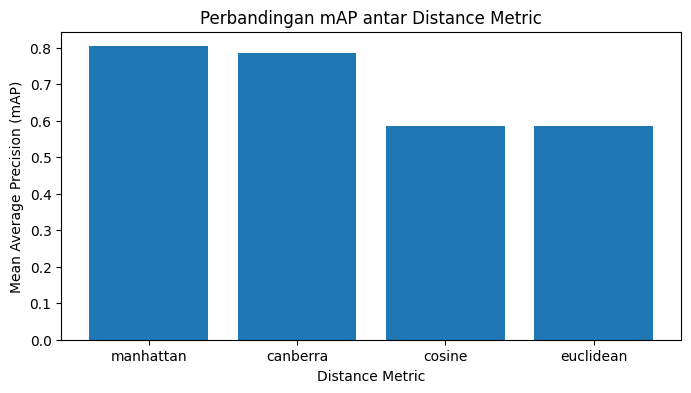

In [46]:
best_distance_row = df_distance_summary.iloc[0]

best_distance = best_distance_row["distance"]
best_map = best_distance_row["mAP"]
best_mrr = best_distance_row["MRR"]

print("Distance terbaik berdasarkan evaluasi global:")
print(f"- Distance Metric : {best_distance}")
print(f"- mAP            : {best_map:.4f}")
print(f"- MRR            : {best_mrr:.4f}")


import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.bar(
    df_distance_summary["distance"],
    df_distance_summary["mAP"]
)
plt.title("Perbandingan mAP antar Distance Metric")
plt.ylabel("Mean Average Precision (mAP)")
plt.xlabel("Distance Metric")
plt.show()


## Visualisasi Query

In [42]:
import matplotlib.pyplot as plt
import cv2

def retrieve_top_k(query_feat, gallery_feats, gallery_labels, k, distance_fn):
    distances = []

    for idx, (feat, label) in enumerate(zip(gallery_feats, gallery_labels)):
        d = distance_fn(query_feat, feat)
        distances.append((d, label, idx))

    distances.sort(key=lambda x: x[0])
    return distances[:k]



import numpy as np

def show_query_results_pretty(
    query_idx,
    distance_fn,
    distance_name,
    top_k=10
):
    q_feat = query_features[query_idx]
    q_label = query_labels[query_idx]
    q_path = df_query.iloc[query_idx]["path"]

    topk = retrieve_top_k(
        q_feat,
        gallery_features,
        gallery_labels,
        k=top_k,
        distance_fn=distance_fn
    )

    plt.figure(figsize=(22, 4))

    # ---- Query Image ----
    plt.subplot(1, top_k + 1, 1)
    q_img = cv2.imread(q_path)
    q_img = cv2.cvtColor(q_img, cv2.COLOR_BGR2RGB)
    plt.imshow(q_img)
    plt.title("QUERY", fontsize=10)
    plt.axis("off")

    # ---- Gallery Results ----
    for rank, (dist, lbl, g_idx) in enumerate(topk, start=1):
        plt.subplot(1, top_k + 1, rank + 1)

        g_path = df_gallery.iloc[g_idx]["path"]
        g_img = cv2.imread(g_path)
        g_img = cv2.cvtColor(g_img, cv2.COLOR_BGR2RGB)
        plt.imshow(g_img)

        status = "BENAR" if lbl == q_label else "SALAH"
        color = "green" if lbl == q_label else "red"

        fname = g_path.split("/")[-1]

        plt.title(
            f"Rank {rank}\n{fname}\n{lbl}\nDist: {dist:.3f}\n[{status}]",
            fontsize=8,
            color=color
        )
        plt.axis("off")

    plt.suptitle(
        f"Top-{top_k} Retrieval Results ({distance_name} Distance)",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()



## Pemanggilan Query

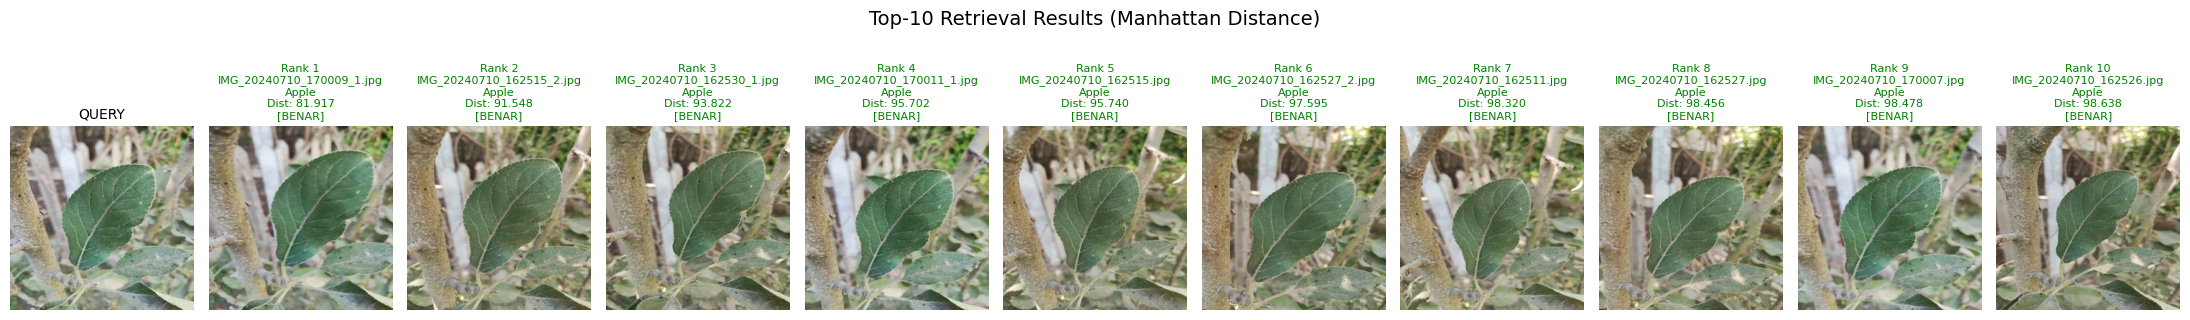

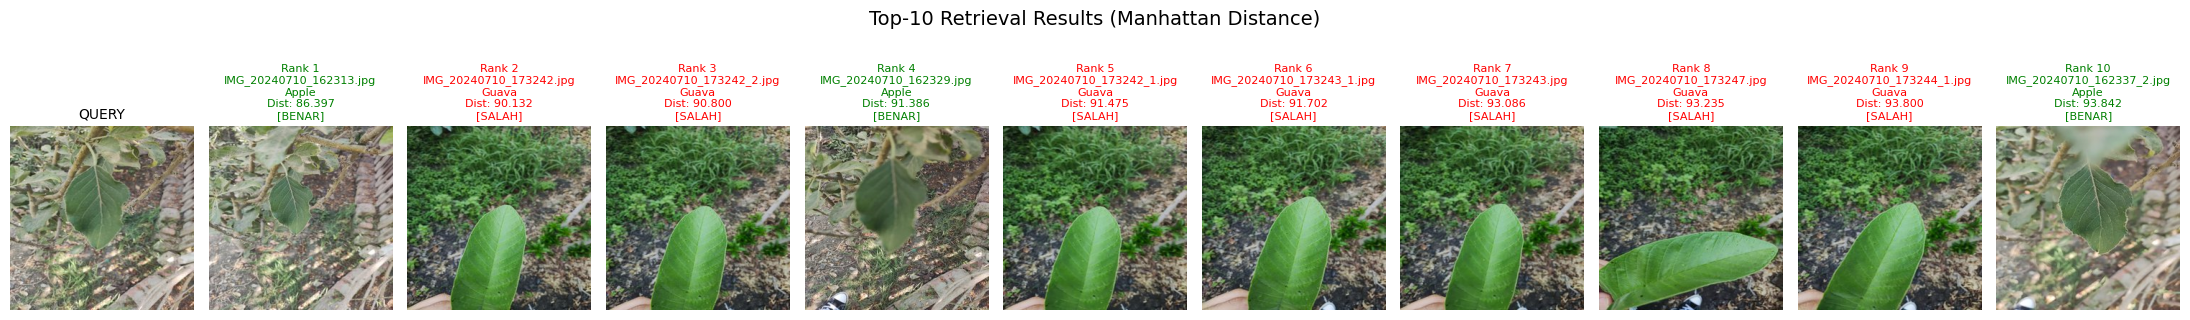

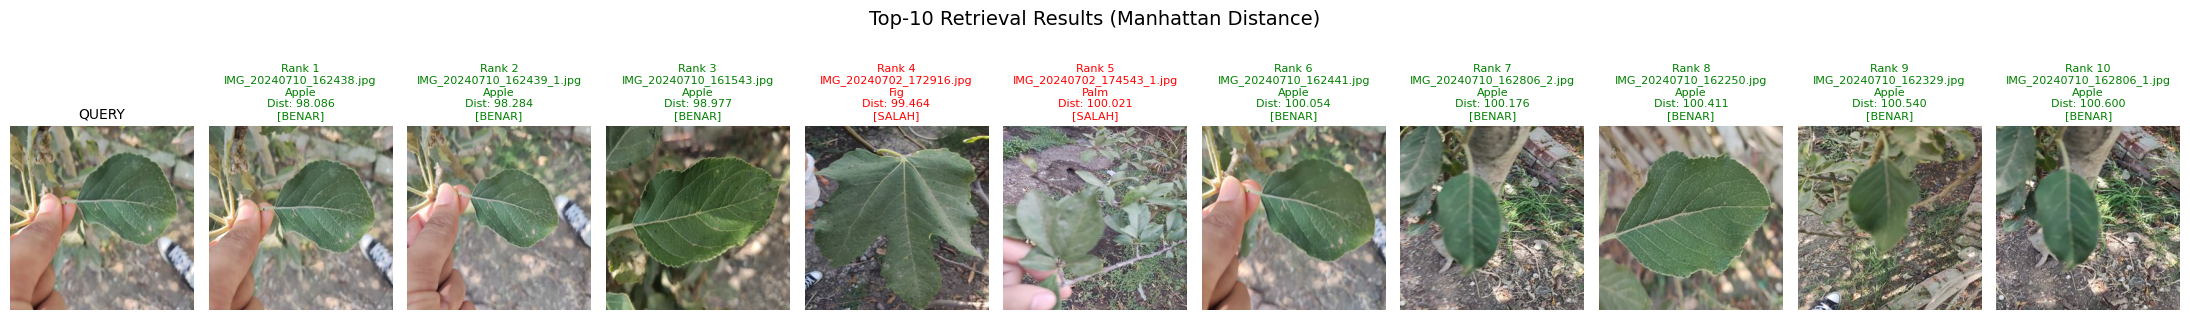

In [43]:
show_query_results_pretty(
    query_idx=0,
    distance_fn=manhattan,
    distance_name="Manhattan"
)

show_query_results_pretty(
    query_idx=5,
    distance_fn=manhattan,
    distance_name="Manhattan"
)

show_query_results_pretty(
    query_idx=12,
    distance_fn=manhattan,
    distance_name="Manhattan"
)
